# Importing Modules

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Data Loading & Reading

In [ ]:
data=pd.read_csv('classroom_logs_rows.csv')

In [ ]:
data.head()

,id,created_at,device_id,window_title,process_name,network_speed_kb,packet_frequency
0,283,2026-06-15 13:44:58.395275+00,cd:33:b0:e9:86:65,dist - File Explorer,explorer.exe,0.16,3
1,284,2026-06-15 13:45:33.861335+00,cd:33:b0:e9:86:65,Task Manager,Taskmgr.exe,1.17,9
2,285,2026-06-15 13:46:09.333273+00,cd:33:b0:e9:86:65,sync - Google Gemini - Google Chrome,chrome.exe,0.07,2
3,286,2026-06-15 13:51:55.563291+00,cd:33:b0:e9:86:65,sync - Google Gemini - Google Chrome,chrome.exe,19.44,87
4,287,2026-06-15 13:56:08.433364+00,cd:33:b0:e9:86:65,Google Gemini - Google Chrome,chrome.exe,20.52,131


# Simple Data Visualaization & Stats

In [ ]:
data.shape

(23847, 7)

In [ ]:
data.iloc[0]

,0
id,283
created_at,2026-06-15 13:44:58.395275+00
device_id,cd:33:b0:e9:86:65
window_title,dist - File Explorer
process_name,explorer.exe
network_speed_kb,0.16
packet_frequency,3


In [ ]:
data.describe()

,id,network_speed_kb,packet_frequency
count,23847.000000,23847.000000,23847.000000
mean,12206.000000,668.473066,720.655344
std,6884.180271,2598.337846,2473.791418
min,283.000000,0.000000,0.000000
25%,6244.500000,20.195000,85.000000
50%,12206.000000,43.850000,162.000000
75%,18167.500000,171.450000,318.000000
max,24129.000000,30054.300000,29269.000000


In [ ]:
data['network_speed_kb'].corr(data['packet_frequency'])

np.float64(0.9951076554003121)

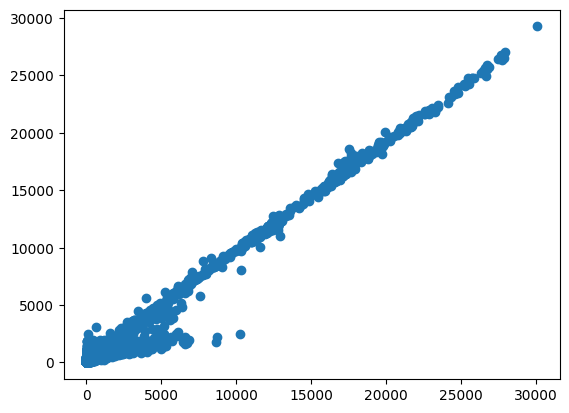

In [ ]:
plt.scatter(x=data['network_speed_kb'],y=data['packet_frequency'])
plt.show()

<Axes: >

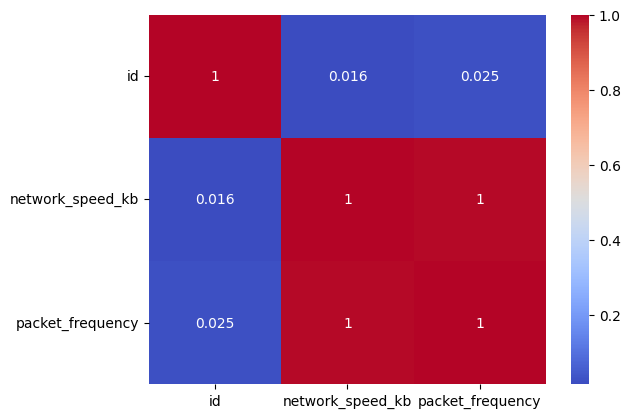

In [ ]:
sns.heatmap(data.corr(numeric_only=True),annot=True,cmap='coolwarm')


<Axes: xlabel='count', ylabel='process_name'>

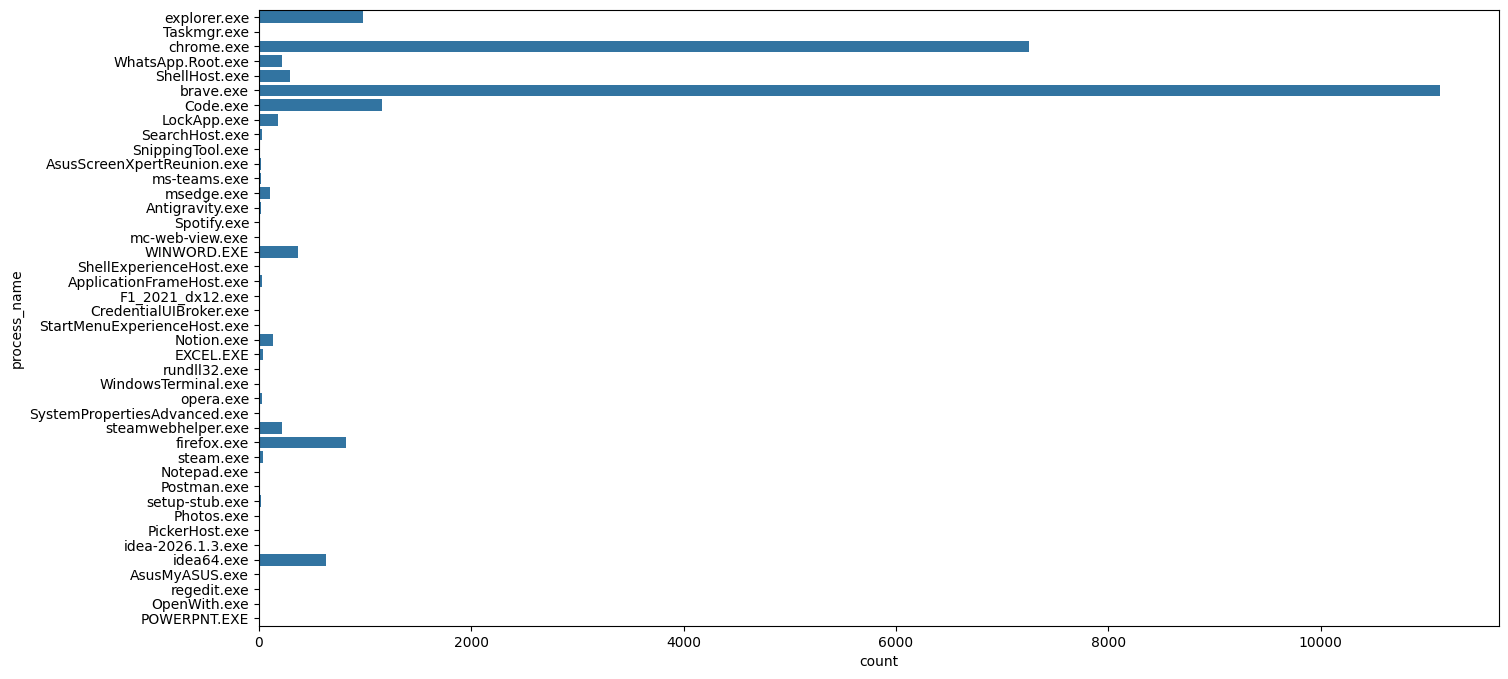

In [ ]:
plt.figure(figsize=(16,8))
sns.countplot(y='process_name',data=data)

In [ ]:
counts=data['window_title'].value_counts()

In [ ]:
counts_less_than_10=counts[counts<10].index.tolist()

In [ ]:
counts_more_than_100=counts[counts>100].index.tolist()


# Data Engineering & Featuring.

### Numerical Engineering

In [ ]:
import pytz

data['created_at'] = pd.to_datetime(data['created_at'], format='mixed', errors='coerce', utc=True)
ist_tz = pytz.timezone('Asia/Kolkata')
data['created_at'] = data['created_at'].dt.tz_convert(ist_tz)

In [ ]:
data=data.drop(columns=["id"])

In [ ]:
data.head()

,created_at,device_id,window_title,process_name,network_speed_kb,packet_frequency
0,2026-06-15 19:14:58.395275+05:30,cd:33:b0:e9:86:65,dist - File Explorer,explorer.exe,0.16,3
1,2026-06-15 19:15:33.861335+05:30,cd:33:b0:e9:86:65,Task Manager,Taskmgr.exe,1.17,9
2,2026-06-15 19:16:09.333273+05:30,cd:33:b0:e9:86:65,sync - Google Gemini - Google Chrome,chrome.exe,0.07,2
3,2026-06-15 19:21:55.563291+05:30,cd:33:b0:e9:86:65,sync - Google Gemini - Google Chrome,chrome.exe,19.44,87
4,2026-06-15 19:26:08.433364+05:30,cd:33:b0:e9:86:65,Google Gemini - Google Chrome,chrome.exe,20.52,131


Calculating scores for each one of them.

In [ ]:
# as both netowrk speed and packet frequency are almost related so we can merge them into one, and create a general score for it.
# as this will be lower our model complexity and make it as a simple strucutre.

'''
We are keeping three checkpoints to mainly check the system robertness
1. scoring index
2. normalize weight index
3. ratio score.

'''

'\nWe are keeping three checkpoints to mainly check the system robertness\n1. scoring index\n2. normalize weight index\n3. ratio score.\n\n'

In [ ]:
data['scoring_index']=(data['network_speed_kb']*data['packet_frequency'])
data['scoring_index']=np.around(data['scoring_index'],2)

In [ ]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

data['normalized_network_speed']=scaler.fit_transform(data[['network_speed_kb']])
data['normalized_packet_frequency']=scaler.fit_transform(data[['packet_frequency']])

In [ ]:
data['normalized_score']=data['normalized_network_speed'] + data['normalized_packet_frequency']

In [ ]:
data['ratio_score']=data['network_speed_kb'] / (data['packet_frequency'] + 1e-5)

In [ ]:
data.head()

,created_at,device_id,window_title,process_name,network_speed_kb,packet_frequency,scoring_index,normalized_network_speed,normalized_packet_frequency,normalized_score,ratio_score
0,2026-06-15 19:14:58.395275+05:30,cd:33:b0:e9:86:65,dist - File Explorer,explorer.exe,0.16,3,0.48,0.000005,0.000102,0.000108,0.053333
1,2026-06-15 19:15:33.861335+05:30,cd:33:b0:e9:86:65,Task Manager,Taskmgr.exe,1.17,9,10.53,0.000039,0.000307,0.000346,0.130000
2,2026-06-15 19:16:09.333273+05:30,cd:33:b0:e9:86:65,sync - Google Gemini - Google Chrome,chrome.exe,0.07,2,0.14,0.000002,0.000068,0.000071,0.035000
3,2026-06-15 19:21:55.563291+05:30,cd:33:b0:e9:86:65,sync - Google Gemini - Google Chrome,chrome.exe,19.44,87,1691.28,0.000647,0.002972,0.003619,0.223448
4,2026-06-15 19:26:08.433364+05:30,cd:33:b0:e9:86:65,Google Gemini - Google Chrome,chrome.exe,20.52,131,2688.12,0.000683,0.004476,0.005158,0.156641


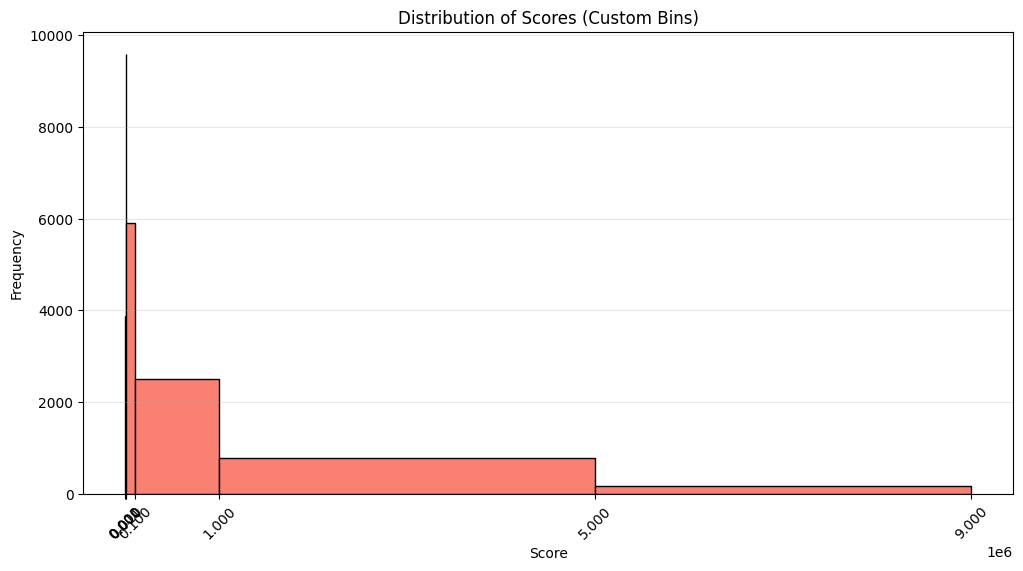

In [ ]:
data_for_plot = data['scoring_index'][data['scoring_index'] > 0]
custom_bins = [0, 1000, 10000, 100000, 1000000, 5000000, 9000000]
plt.figure(figsize=(12, 6))
plt.hist(data['scoring_index'], bins=custom_bins, color='salmon', edgecolor='black')
plt.title('Distribution of Scores (Custom Bins)')
plt.xlabel('Score')
plt.ylabel('Frequency')
plt.xticks(custom_bins, rotation=45) # Force labels to show all bin edges
plt.grid(axis='y', alpha=0.3)
plt.show()

### Text Data engineering

In [ ]:
'''
now we have two categorical features, which can be used to train the model actually an nlp model to look into the word of
process name and window title and tells which category this website lies into.

1. Process Maping
2. Window Title Maping.

'''

'\nnow we have two categorical features, which can be used to train the model actually an nlp model to look into the word of\nprocess name and window title and tells which category this website lies into.\n\n1. Process Maping\n2. Window Title Maping.\n\n'

In [ ]:
data['process_name'].value_counts()

,count
process_name,
brave.exe,11123
chrome.exe,7253
Code.exe,1161
explorer.exe,985
firefox.exe,820
idea64.exe,630
WINWORD.EXE,371
ShellHost.exe,289
steamwebhelper.exe,217


In [ ]:
# process_categories=["Development","Browser","System","Games","Social_App","Educational_App"]
# process_categories = [
#     "Development",
#     "Browser",
#     "System",
#     "Games",
#     "Social_App",
#     "Educational_App",
#     "Productivity"
# ]

In [ ]:
regex_pattern = r'\s*-\s*(Google Chrome|Brave|Mozilla Firefox|Microsoft Edge)\s*$'
data['cleaned_window_title'] = data['window_title'].astype(str)
data['cleaned_window_title']=data['cleaned_window_title'].replace(regex_pattern,'',regex=True)

In [ ]:
unique_words=data['cleaned_window_title'].unique()
print(f" Total number of unique words :- {len(unique_words)}")

 Total number of unique words :- 2118


In [ ]:
# loading a clustering model and embedding model to establish a relationship between process name and window title.
from sentence_transformers import SentenceTransformer
from sklearn.cluster import HDBSCAN

In [ ]:
model = SentenceTransformer('BAAI/bge-small-en-v1.5')

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/366 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [ ]:
embeddingss=model.encode(unique_words,show_progress_bar=True)

Batches:   0%|          | 0/67 [00:00<?, ?it/s]

In [ ]:
clusterer = HDBSCAN(min_cluster_size=15, min_samples=5, metric='euclidean')
cluster_labels = clusterer.fit_predict(embeddingss)

In [ ]:
title_to_cluster = dict(zip(unique_words, cluster_labels))
data['text_cluster'] = data['cleaned_window_title'].map(title_to_cluster)

In [ ]:
print(data[['cleaned_window_title', 'text_cluster']].head(10))

   cleaned_window_title  text_cluster
0  dist - File Explorer            15
1          Task Manager            -1
2  sync - Google Gemini            11
3  sync - Google Gemini            11
4         Google Gemini            11
5  sync - Google Gemini            11
6              WhatsApp            10
7  sync - Google Gemini            11
8               New tab            -1
9                 Gmail            -1


# Hybrid & Dataset Spliting.

In [ ]:
from sklearn.model_selection import train_test_split

train_df, test_df=train_test_split(data,test_size=0.2,random_state=42)

In [ ]:
# we are calculating avg network speed for each group.
cluster_speed_map=train_df.groupby('text_cluster')['network_speed_kb'].mean().to_dict()

# mapping it back as continuous feature.
train_df['cluster_mean_speed']=np.around(train_df['text_cluster'].map(cluster_speed_map),2)
test_df['cluster_mean_speed']=np.around(test_df['text_cluster'].map(cluster_speed_map),2)

# looking for global mean speed in case the newer might have a cases of nan.
global_train_mean = train_df['network_speed_kb'].mean()
test_df['cluster_mean_speed'] = test_df['cluster_mean_speed'].fillna(global_train_mean)

# Model Creation

### Anomaly Detection

In [ ]:
from sklearn.ensemble import IsolationForest

anomaly_features = ['normalized_score', 'ratio_score', 'cluster_mean_speed']

# 2. Initialize the Isolation Forest
# contamination=0.05 assumes roughly 5% of the raw logs might be highly irregular bursts
iso_forest = IsolationForest(contamination=0.05, random_state=42)

# 3. Fit on TRAINING data only to prevent data leakage
iso_forest.fit(train_df[anomaly_features])

# 4. Predict anomaly flags (-1 for anomaly, 1 for normal) for both sets
train_df['is_anomaly'] = iso_forest.predict(train_df[anomaly_features])
test_df['is_anomaly'] = iso_forest.predict(test_df[anomaly_features])

print(train_df[['cleaned_window_title', 'is_anomaly']].head(10))

                                    cleaned_window_title  is_anomaly
12105  CPT TCS Test (New Pattern) - 07 - Bullseye Onl...           1
2312   Prank Call के चक्कर में Bapuji पहुँचे जुए के अ...           1
6826                                             ChatGPT           1
13676  Cognizant DEEPSkilling Program Preparation - G...           1
19475  Maximize the Number of Target Nodes After Conn...           1
21517  Disjoint Set Union Explained and Implemented -...           1
13430  Maximum Subarray Sum With Length Divisible by ...           1
5477                                            Cineplay           1
17789     Safest Path Grid Clarification - Google Gemini           1
10819  Anime Attack on Titan: Final Season, Part 2 Ep...           1


### Neural Network Design

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

In [ ]:
class ClassroomSequenceDataset(Dataset):
    def __init__(self, dataframe, feature_cols, seq_length=30):
        """
        Args:
            dataframe (pd.DataFrame): The engineered, split dataframe (Train or Test).
            feature_cols (list): List of column names to use as input features.
            target_col (str): The column name of your target label (e.g., 'is_distracted').
            seq_length (int): How many consecutive log rows to look back on.
        """
        self.seq_length = seq_length

        # Extract features as continuous numpy arrays
        self.features = dataframe[feature_cols].values.astype(np.float32)

        # Calculate how many valid overlapping sequences we can create
        self.num_sequences = len(dataframe) - seq_length + 1

    def __len__(self):
        return self.num_sequences

    def __getitem__(self, idx):
        # 1. Grab a continuous sliding window slice of size 'seq_length'
        x_seq = self.features[idx : idx + self.seq_length]

        # Convert to PyTorch Tensors
        return torch.tensor(x_seq)

In [ ]:
# columns for decidig the distracting factor.
feature_columns = [
    'normalized_score',
    'ratio_score',
    'text_cluster',
    'cluster_mean_speed',
    'is_anomaly'
]


In [ ]:
scaler = StandardScaler()

train_df_scaled = train_df.copy()
test_df_scaled = test_df.copy()

train_df_scaled[feature_columns] = scaler.fit_transform(train_df[feature_columns])
test_df_scaled[feature_columns] = scaler.transform(test_df[feature_columns])

In [ ]:
# Initialize the training dataset (looking back at 30-step history windows)
train_dataset = ClassroomSequenceDataset(
    dataframe=train_df_scaled,
    feature_cols=feature_columns,
    seq_length=30
)

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=False,         # Keep sequence chronological for unsupervised tracking
    drop_last=True
)

In [ ]:
# Quick validation check of shape
sample_x = next(iter(train_loader))
print(f"Batch Features Shape: {sample_x.shape}")

Batch Features Shape: torch.Size([64, 30, 5])


# LSTM Building

In [ ]:
import torch.nn as nn

In [ ]:

class LSTMAutoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, seq_len):
        super(LSTMAutoencoder, self).__init__()
        self.seq_len = seq_len
        self.input_dim = input_dim

        # 1. ENCODER: Compresses the sequence over time
        self.encoder_lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=2,
            batch_first=True,
            dropout=0.2
        )

        # 2. DECODER: Reconstructs the compressed vector back into a sequence
        self.decoder_lstm = nn.LSTM(
            input_size=hidden_dim,
            hidden_size=hidden_dim,
            num_layers=2,
            batch_first=True,
            dropout=0.2
        )

        # 3. OUTPUT LAYER: Maps hidden states back to the original 5 features
        self.output_layer = nn.Linear(hidden_dim, input_dim)


    def forward(self, x):
        # x shape: (Batch, Seq_Len, Input_Dim) -> e.g., (64, 30, 5)

        # Pass through Encoder
        # We only care about the final hidden state (hn) which represents the summary memory
        _, (hn, _) = self.encoder_lstm(x)

        # Take the top layer's hidden state: shape (Batch, Hidden_Dim)
        hidden_summary = hn[-1]

        # Repeat the summary vector 'seq_len' times to recreate the time dimension
        # Shape becomes: (Batch, Seq_Len, Hidden_Dim)
        decoder_input = hidden_summary.unsqueeze(1).repeat(1, self.seq_len, 1)

        # Pass through Decoder
        decoder_out, _ = self.decoder_lstm(decoder_input)

        # Map back to original feature space
        # Shape becomes: (Batch, Seq_Len, Input_Dim)
        predictions = self.output_layer(decoder_out)

        return predictions

In [ ]:
# 5 features: normalized_score, ratio_score, text_cluster, cluster_mean_speed, is_anomaly
INPUT_DIM = 5
HIDDEN_DIM = 32 # Size of the compressed memory vector
SEQ_LEN = 30   # 30-second history window

In [ ]:
model = LSTMAutoencoder(input_dim=INPUT_DIM, hidden_dim=HIDDEN_DIM, seq_len=SEQ_LEN)
print(model)

LSTMAutoencoder(
  (encoder_lstm): LSTM(5, 32, num_layers=2, batch_first=True, dropout=0.2)
  (decoder_lstm): LSTM(32, 32, num_layers=2, batch_first=True, dropout=0.2)
  (output_layer): Linear(in_features=32, out_features=5, bias=True)
)


In [ ]:
# Test a single forward pass with your loader's sample batch

with torch.no_grad():
    sample_output = model(sample_x)

print(f"Input Shape:  {sample_x.shape}")
print(f"Output Shape: {sample_output.shape}")

Input Shape:  torch.Size([64, 30, 5])
Output Shape: torch.Size([64, 30, 5])


# Training

In [ ]:
import torch.optim as optim

# 1. Hyperparameters & Optimization Setup
EPOCHS = 20
LEARNING_RATE = 0.001
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Move model to GPU if available (your HP Victus has a GTX 1650!)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

print(f"Training on device: {device}")

# 2. The Core Training Loop
model.train()
for epoch in range(EPOCHS):
    total_loss = 0.0
    for batch_x in train_loader:
        # Move batch data to the active device
        batch_x = batch_x.to(device)

        # Forward pass
        predictions = model(batch_x)
        loss = criterion(predictions, batch_x) # Compare output directly back to input

        # Backward pass and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * batch_x.size(0)

    epoch_loss = total_loss / len(train_loader.dataset)
    print(f"Epoch [{epoch+1}/{EPOCHS}] | Average Sequence MSE Loss: {epoch_loss:.6f}")

Training on device: cuda
Epoch [1/20] | Average Sequence MSE Loss: 0.987697
Epoch [2/20] | Average Sequence MSE Loss: 0.976612
Epoch [3/20] | Average Sequence MSE Loss: 0.965550
Epoch [4/20] | Average Sequence MSE Loss: 0.950069
Epoch [5/20] | Average Sequence MSE Loss: 0.928189
Epoch [6/20] | Average Sequence MSE Loss: 0.909358
Epoch [7/20] | Average Sequence MSE Loss: 0.884431
Epoch [8/20] | Average Sequence MSE Loss: 0.860337
Epoch [9/20] | Average Sequence MSE Loss: 0.837200
Epoch [10/20] | Average Sequence MSE Loss: 0.811157
Epoch [11/20] | Average Sequence MSE Loss: 0.794567
Epoch [12/20] | Average Sequence MSE Loss: 0.783966
Epoch [13/20] | Average Sequence MSE Loss: 0.743009
Epoch [14/20] | Average Sequence MSE Loss: 0.714657
Epoch [15/20] | Average Sequence MSE Loss: 0.697197
Epoch [16/20] | Average Sequence MSE Loss: 0.717329
Epoch [17/20] | Average Sequence MSE Loss: 0.691967
Epoch [18/20] | Average Sequence MSE Loss: 0.679501
Epoch [19/20] | Average Sequence MSE Loss: 0.691

In [ ]:
train_df.columns

Index(['created_at', 'device_id', 'window_title', 'process_name',
       'network_speed_kb', 'packet_frequency', 'scoring_index',
       'normalized_network_speed', 'normalized_packet_frequency',
       'normalized_score', 'ratio_score', 'cleaned_window_title',
       'text_cluster', 'cluster_mean_speed', 'is_anomaly'],
      dtype='object')

# Anomaly Threshold

In [ ]:

model.eval() # Switch to evaluation mode (turns off dropout)
all_losses = []

with torch.no_grad():
    for batch_x in train_loader:
        batch_x = batch_x.to(device)
        predictions = model(batch_x)

        # Calculate MSE loss row-by-row within the batch
        # This gives us the error profile per individual 30-second window
        mse_per_sequence = torch.mean((predictions - batch_x) ** 2, dim=(1, 2))
        all_losses.extend(mse_per_sequence.cpu().numpy())

# Convert to numpy array
all_losses = np.array(all_losses)

# Calculate the 95th percentile threshold
anomaly_threshold = np.percentile(all_losses, 95)

print(f"--- Threshold Assessment ---")
print(f"Minimum Reconstruction Error: {all_losses.min():.4f}")
print(f"Average Reconstruction Error: {all_losses.mean():.4f}")
print(f"Max Reconstruction Error:     {all_losses.max():.4f}")
print(f"Calculated 95% Threshold:     {anomaly_threshold:.4f}")


--- Threshold Assessment ---
Minimum Reconstruction Error: 0.1388
Average Reconstruction Error: 0.6578
Max Reconstruction Error:     4.4661
Calculated 95% Threshold:     1.4448


# Evaluating Phase

In [ ]:
# 1. Package the test data using the exact same sequence window configuration
test_dataset = ClassroomSequenceDataset(
    dataframe=test_df_scaled,
    feature_cols=feature_columns,
    seq_length=30
)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, drop_last=False)

model.eval()
test_losses = []

# 2. Extract reconstruction errors for the unseen data
with torch.no_grad():
    for batch_x in test_loader:
        batch_x = batch_x.to(device)
        predictions = model(batch_x)
        mse_per_sequence = torch.mean((predictions - batch_x) ** 2, dim=(1, 2))
        test_losses.extend(mse_per_sequence.cpu().numpy())

test_losses = np.array(test_losses)

# 3. Flag sequences exceeding our training threshold
flagged_anomalies = test_losses > anomaly_threshold
anomaly_percentage = (flagged_anomalies.sum() / len(test_losses)) * 100

print(f"--- Test Data Evaluation ---")
print(f"Total Test Sequences Scanned: {len(test_losses)}")
print(f"Number of Flagged Security Anomalies: {flagged_anomalies.sum()}")
print(f"Anomaly Detection Rate: {anomaly_percentage:.2f}%")

--- Test Data Evaluation ---
Total Test Sequences Scanned: 4741
Number of Flagged Security Anomalies: 446
Anomaly Detection Rate: 9.41%


# Inspecting The Culprits (Explainable AI)

In [ ]:
# Create an array matching row-indices of test_df to the test_losses
# The target index for a sequence is its final row (idx + seq_length - 1)
seq_length = 30
anomaly_indices = []

for idx, is_anon in enumerate(flagged_anomalies):
    if is_anon:
        # Map the sequence back to the original test_df row index
        actual_row_idx = test_df.index[idx + seq_length - 1]
        anomaly_indices.append(actual_row_idx)

# Pull the original, unscaled logs for the flagged rows
flagged_logs = test_df.loc[anomaly_indices]

print("--- TOP 10 DETECTED BEHAVIORAL ANOMALIES ---")
print(flagged_logs[['cleaned_window_title', 'network_speed_kb', 'text_cluster']].head(10))

--- TOP 10 DETECTED BEHAVIORAL ANOMALIES ---
                                    cleaned_window_title  network_speed_kb  \
4343   A Comparative Study of HMM, CRF, Bi-LSTM, and ...             20.79   
6503   Minimum Insertion Steps to Make a String Palin...          19517.30   
7112         Competitive Programming LPU - Google Sheets              2.29   
23232  Absolute Batman Issue 1 (2024) - Read Free Com...             52.48   
19463  You searched for the 100 - MoviesMod | Movies ...             41.65   
1940     saurabhkumar005/syncmate-backend - Docker Image              0.00   
19162                                    Registry Editor             20.97   
16702         Find a Safe Walk Through a Grid - LeetCode             24.49   
19871  A Comparative Study of HMM, CRF, Bi-LSTM, and ...          12761.70   
19444  TCS Stock Down ~37% in 1 year -Is This Just a ...            105.86   

       text_cluster  
4343              3  
6503             11  
7112             -1  
23232   

# Saving the Model

In [ ]:
import torch
import joblib
import json
import os

def export_model_artifacts(model, scaler, iso_forest, cluster_speed_map, anomaly_threshold, export_dir="vigilance_ai_export"):
    """
    Serializes and packages all machine learning and feature engineering dependencies
    to disk for seamless initialization within a live production environment.
    """
    os.makedirs(export_dir, exist_ok=True)

    # 1. Save PyTorch LSTM Autoencoder Weights
    torch.save(model.state_dict(), os.path.join(export_dir, "lstm_autoencoder.pth"))

    # 2. Save Scikit-Learn Preprocessing & Base Anomaly Models
    joblib.dump(scaler, os.path.join(export_dir, "standard_scaler.joblib"))
    joblib.dump(iso_forest, os.path.join(export_dir, "isolation_forest.joblib"))

    # 3. Save Empirical Baselines and Operational Boundaries
    metadata = {
        "anomaly_threshold": float(anomaly_threshold),
        "cluster_speed_map": {str(k): float(v) for k, v in cluster_speed_map.items()}
    }
    with open(os.path.join(export_dir, "pipeline_metadata.json"), "w") as f:
        json.dump(metadata, f, indent=4)

    print(f"[SUCCESS] All 4 structural artifacts successfully serialized to directory: '{export_dir}/'")

# Run the export function instantly
export_model_artifacts(
    model=model,
    scaler=scaler,
    iso_forest=iso_forest,
    cluster_speed_map=cluster_speed_map,
    anomaly_threshold=anomaly_threshold
)

[SUCCESS] All 4 structural artifacts successfully serialized to directory: 'vigilance_ai_export/'
